# Diversification opportunity ceilings and revenue-risk frontiers

We separate three questions: **Was safer selection possible? Could historical estimates find it? How much revenue did it cost?**

Choose exactly 100 historically eligible merchants. Expected return remains historical mean monthly gross fees. Freeze expected-fee floors of **99.5%, 99%, 98%, 95%**, both existing covariance methods, and all practical selections before using future outcomes. Revenue-only is the 100% anchor.

Primary: eight November 2021-June 2022 cutoffs, 26-week histories. Sensitivity: 26 versus 52 weeks on the same five February-June cutoffs. September selections are unscored.

## Definitions and controls

Practical optimization minimizes $z^T\widehat\Sigma z$, subject to $z_i\in\{0,1\}$, $\sum z_i=100$ and $\mu^Tz\ge r\mu^Tz_B$. Raw and detrended covariance retain the original variance-preserving shrinkage and fixed solver budgets. All eligible merchants remain candidates.

**Revenue:** every day of the following three complete calendar months. **Variability:** sample SD over complete Monday-Sunday weeks wholly inside those months. **Relative variability:** SD / actual weekly mean.

**Downside:** $D=\sqrt{\operatorname{mean}(\max(T-\sum_i z_iF_{i,w},0)^2)}$. At every cutoff, $T$ is the revenue-only portfolio's latest-26-week mean, identical across every method, floor and lookback. Sum merchant fees before calculating shortfalls. For summaries, average $D/T$ across all origins, including zeros.

A 5% improvement is a fixed research screen, not a validated business requirement. Practical investigation also requires average realized fee retention at its floor and joint risk/fee improvement in at least six of eight tests. Zero-downside ties are not wins.

## Reproduce in four stages

From the repository root, with existing `code/requirements-forecast.txt` dependencies:

```text
python code/scripts/diversification_frontier.py select
python code/scripts/diversification_frontier.py evaluate
python code/scripts/diversification_frontier.py oracle
python code/scripts/diversification_frontier.py report
```

`python code/scripts/diversification_frontier.py all` performs all four stages. Repeating them recomputes the searches and compares exact result digests. Evaluation rejects missing/changed selection manifests. This notebook reads the resulting artifacts and regenerates presentation outputs; it does not retune selections. No API, GPU or new optimizer dependency is needed.

In [1]:
from pathlib import Path
import sys
import json
import io
from contextlib import redirect_stdout
import pandas as pd
from IPython.display import display, Markdown, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code/scripts').is_dir() and (p / 'handoff').is_dir())
sys.path.insert(0, str(root / 'code/scripts'))
import diversification_frontier as study
out = study.OUT
study.validate_freeze()
with redirect_stdout(io.StringIO()):
    study.report_stage()
metrics = pd.read_parquet(out / 'frontier_metrics.parquet')
summary = pd.read_parquet(out / 'summary.parquet')
oracles = pd.read_parquet(out / 'oracle_bounds.parquet')
checks = json.loads((out / 'acceptance_checks.json').read_text())
display(pd.Series(checks, name='Acceptance evidence').to_frame())

,Acceptance evidence
original_99_exact_reproduction,True
previous_outputs_unchanged,True
all_practical_frozen_before_outcomes,True
input_audit_verified,True
exactly_100_eligible_expected_floors,True
common_reference_all_grid,True
independent_daily_quarter_weekly_reconciliations,245
protected_realized_constraints,True
objective_reconciliations,True
nested_bounds,True


## Estimated and realized frontiers

These are discrete tested points, not a guaranteed smooth efficient frontier. Lines connect points for readability. Dominated and unsuccessful points remain visible. Estimated raw and detrended risks have different definitions; compare each against its own baseline. The realized plots use a common observed outcome for every method.

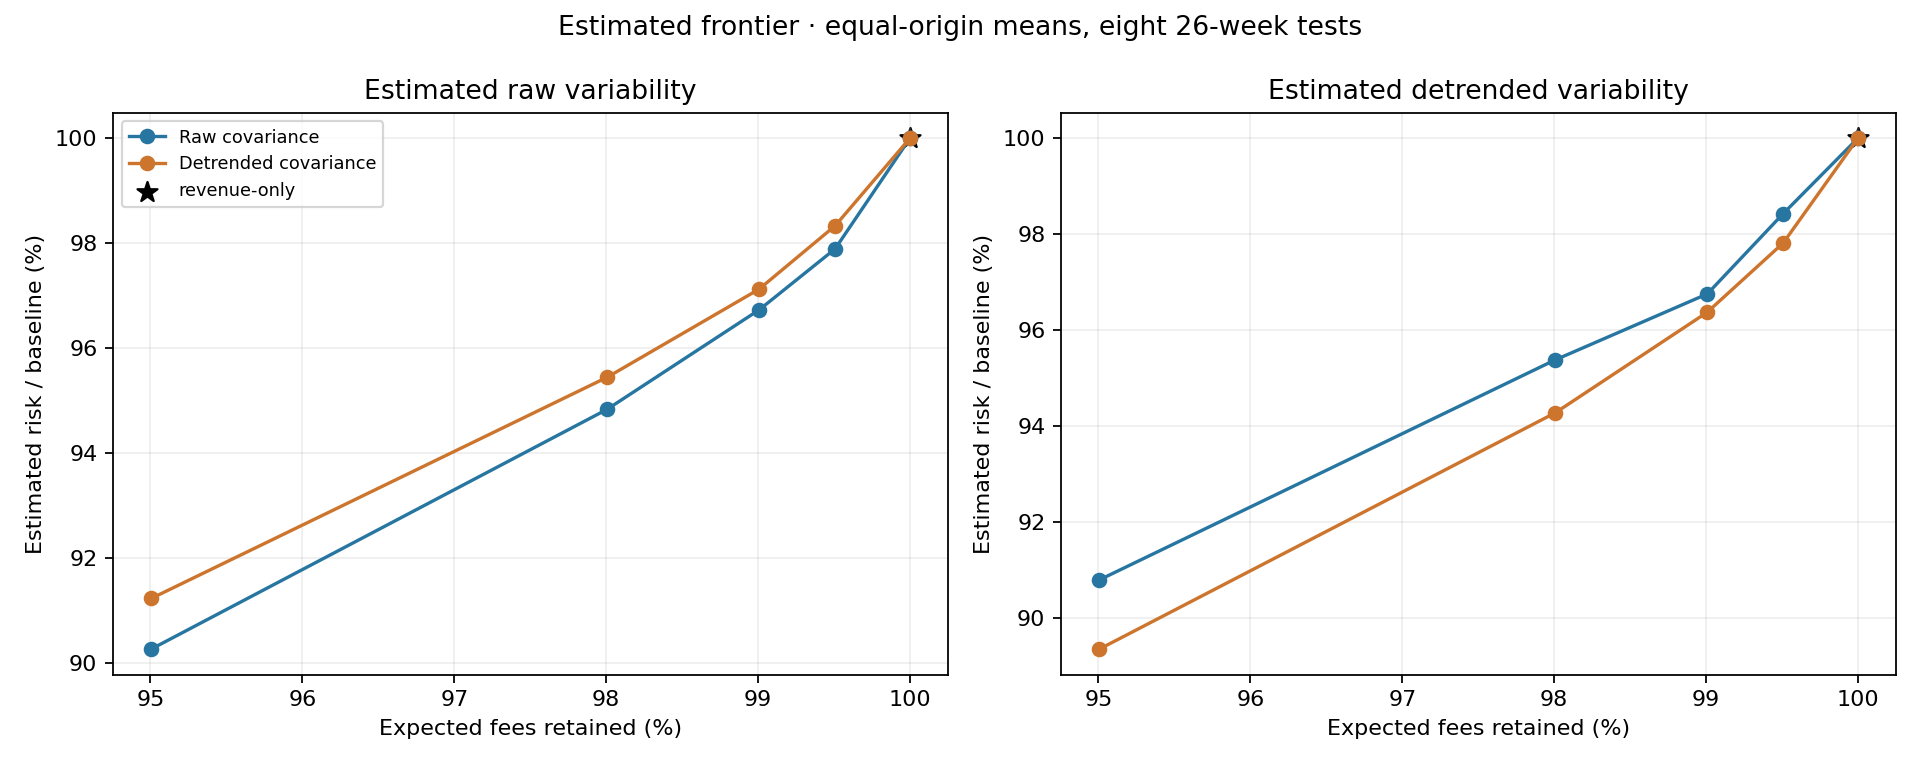

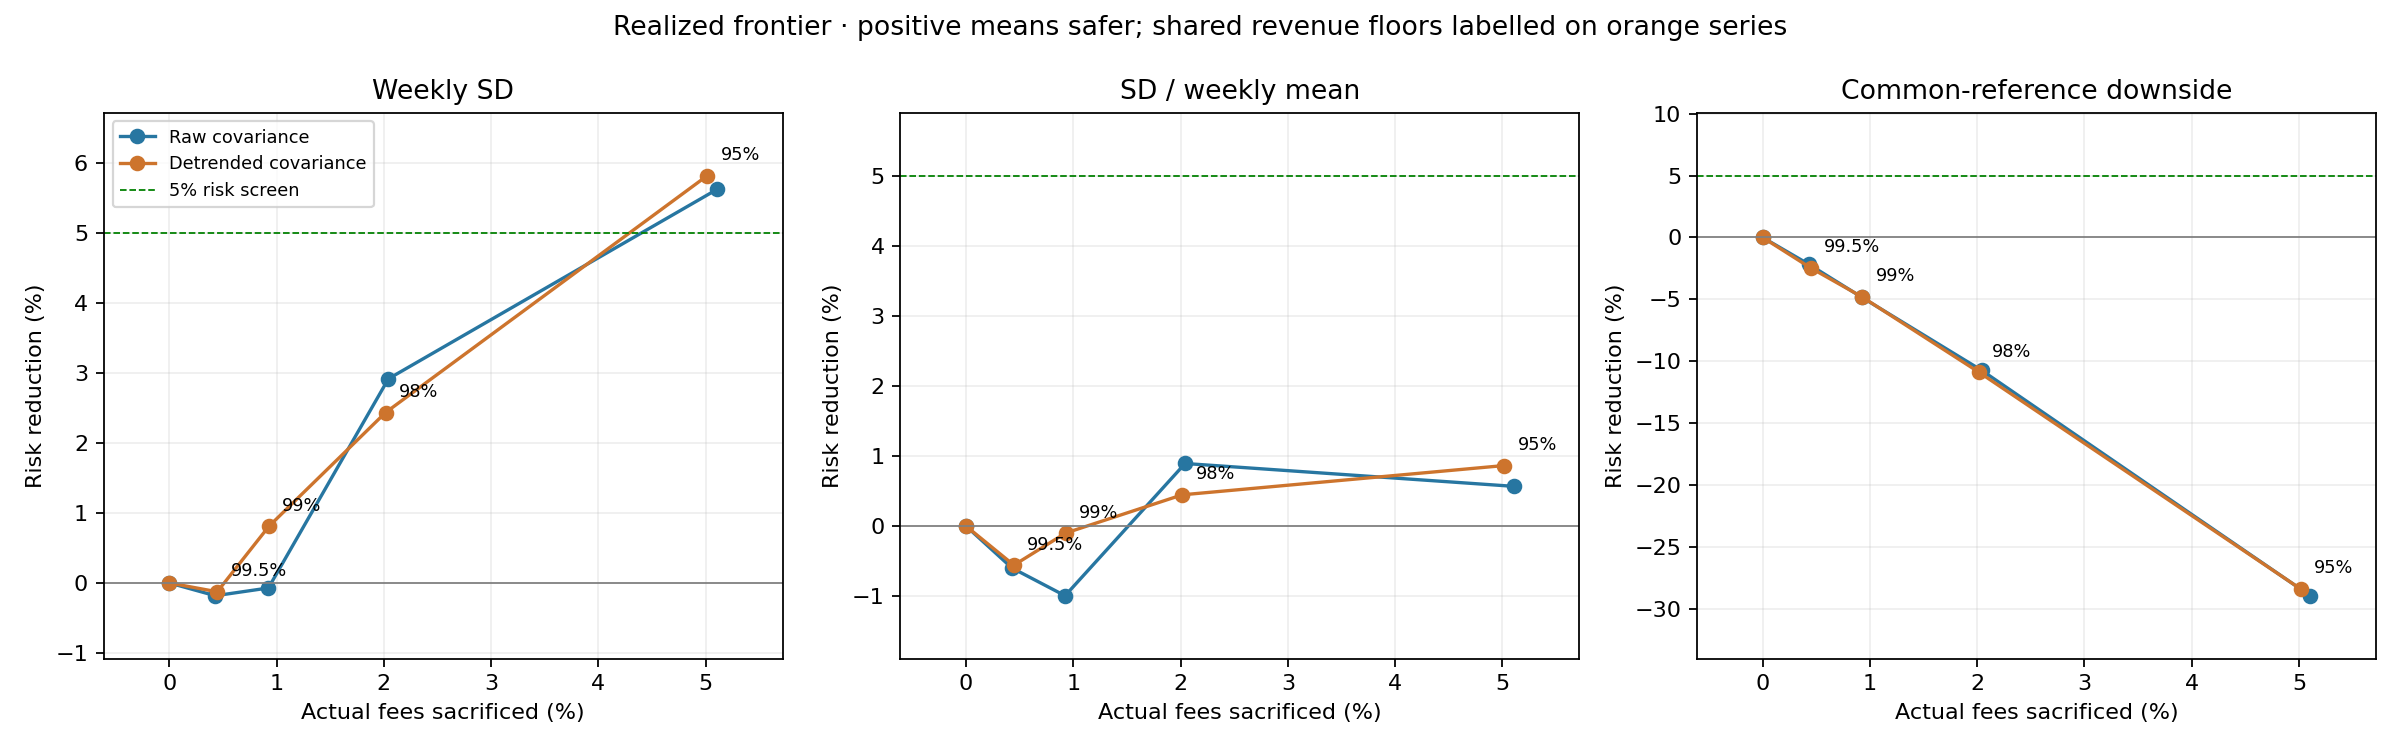

In [2]:
display(Image(filename=str(out / 'plots/estimated_frontier.png')))
display(Image(filename=str(out / 'plots/realized_frontier.png')))

In [3]:
primary = summary.loc[summary.comparison.eq('primary_26w_eight')]
columns = ['method','retention','mean_actual_fee_retention_pct','mean_sd_reduction_pct',
           'mean_cv_reduction_pct','normalized_downside_reduction_pct','sd_joint_successes',
           'downside_joint_successes','investigate_sd','investigate_downside']
display(primary[columns].round(4))
display(metrics.loc[metrics.window.eq('26w') & metrics.status.eq('observed'),
    ['as_of','method','retention','actual_fee_retention_pct','sd_reduction_pct',
     'normalized_downside','actual_fee_guardrail_met','future_weeks']].round(4))

,method,retention,mean_actual_fee_retention_pct,mean_sd_reduction_pct,mean_cv_reduction_pct,normalized_downside_reduction_pct,sd_joint_successes,downside_joint_successes,investigate_sd,investigate_downside
0,detrended_risk,0.950,94.9841,5.8202,0.8633,-28.3885,4,0,False,False
1,detrended_risk,0.980,97.9848,2.4342,0.4458,-10.8758,3,0,False,False
2,detrended_risk,0.990,99.0720,0.8094,-0.0997,-4.8098,4,0,False,False
3,detrended_risk,0.995,99.5537,-0.1260,-0.5573,-2.4523,4,0,False,False
4,raw_risk,0.950,94.8949,5.6222,0.5670,-28.9298,3,0,False,False
5,raw_risk,0.980,97.9577,2.9168,0.8927,-10.7354,2,0,False,False
6,raw_risk,0.990,99.0768,-0.0718,-0.9935,-4.8249,4,0,False,False
7,raw_risk,0.995,99.5721,-0.1824,-0.5974,-2.1545,4,0,False,False


,as_of,method,retention,actual_fee_retention_pct,sd_reduction_pct,normalized_downside,actual_fee_guardrail_met,future_weeks
0,2021-11-30,revenue_only,1.000,100.0000,0.0000,0.1831,True,12
1,2021-11-30,raw_risk,0.995,99.6945,0.4405,0.1840,True,12
2,2021-11-30,detrended_risk,0.995,99.5119,0.5428,0.1856,True,12
3,2021-11-30,raw_risk,0.990,99.1836,1.0907,0.1869,True,12
4,2021-11-30,detrended_risk,0.990,99.0041,1.1674,0.1886,True,12
...,...,...,...,...,...,...,...,...
103,2022-06-30,detrended_risk,0.990,99.1950,7.2491,0.0000,True,12
104,2022-06-30,raw_risk,0.980,97.9549,9.4819,0.0000,False,12
105,2022-06-30,detrended_risk,0.980,98.2584,9.4342,0.0000,True,12
106,2022-06-30,raw_risk,0.950,95.1276,12.3243,0.0000,True,12


## Hindsight diagnostics: never deploy these selections

The variability oracle minimizes observed future **sample variance without shrinkage**. The downside oracle minimizes squared shortfalls directly. Both have the same historical eligibility and expected-fee floor as practical methods. The **income-protected** version additionally retains the corresponding fraction of actual full-quarter baseline fees.

Feasible solutions give achievable risk reductions. Valid global lower bounds limit any further possible gain. Square-rooted objective bounds are intervals for achievable SD/RMS downside, **not statistical confidence intervals**. A case is demonstrated, ruled out by the bound, unresolved, or has zero baseline risk. Unfinished optimization cannot prove no opportunity.

Hindsight searches start only after practical selections are frozen and scored. Search budgets are fixed; second-tier work continues only when uncertified. These future-aware lists are stored separately under `hindsight_only/`.

An oracle can exploit chance in a short observed path. Demonstrated hindsight opportunity does not prove the improvement could have been forecast.

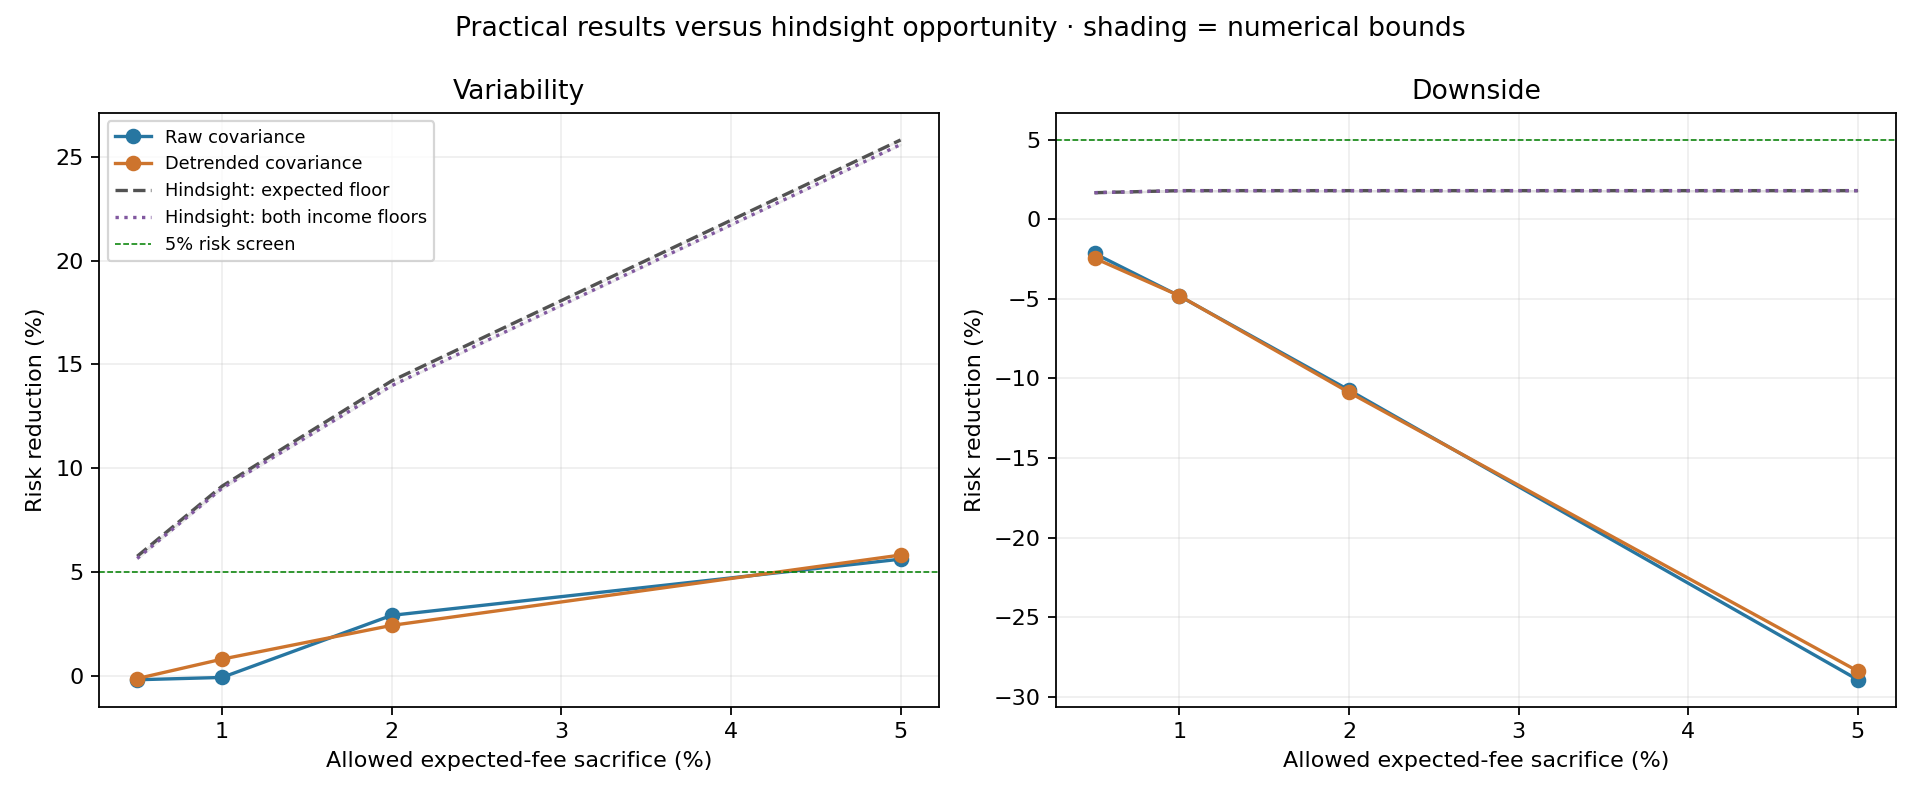

opportunity                             demonstrated  no_baseline_risk  \
objective   regime           retention                                   
downside    income_protected 0.950                 1                 2   
                             0.980                 1                 2   
                             0.990                 1                 2   
                             0.995                 1                 2   
            matched          0.950                 1                 2   
                             0.980                 1                 2   
                             0.990                 1                 2   
                             0.995                 1                 2   
variability income_protected 0.950                 8                 0   
                             0.980                 7                 0   
                             0.990                 7                 0   
                             0.995                 6                 0   
            matched          0.950                 8                 0   
                             0.980                 7                 0   
                             0.990                 7                 0   
                             0.995                 6                 0   

opportunity                             ruled_out_by_bound  
objective   regime           retention                      
downside    income_protected 0.950                       5  
                             0.980                       5  
                             0.990                       5  
                             0.995                       5  
            matched          0.950                       5  
                             0.980                       5  
                             0.990                       5  
                             0.995                       5  
variability income_protected 0.950                       0  
                             0.980                       1  
                             0.990                       1  
                             0.995                       2  
            matched          0.950                       0  
                             0.980                       1  
                             0.990                       1  
                             0.995                       2

In [4]:
display(Image(filename=str(out / 'plots/practical_vs_hindsight.png')))
display(oracles.groupby(['objective','regime','retention','opportunity']).size().unstack(fill_value=0))

In [5]:
display(oracles[['as_of','objective','regime','retention','actual_fee_retention_pct','demonstrated_reduction_pct','possible_reduction_pct','opportunity','certified','gap_upper_fraction']].round(5))
display(pd.read_parquet(out / 'oracle_summary.parquet').round(4))

,as_of,objective,regime,retention,actual_fee_retention_pct,demonstrated_reduction_pct,possible_reduction_pct,opportunity,certified,gap_upper_fraction
0,2021-11-30,variability,matched,0.995,99.47773,1.89948,1.90810,ruled_out_by_bound,True,0.00018
1,2021-11-30,variability,income_protected,0.995,99.55687,1.87066,1.88185,ruled_out_by_bound,True,0.00023
2,2021-11-30,downside,matched,0.995,100.24562,1.81261,1.81261,ruled_out_by_bound,True,0.00000
3,2021-11-30,downside,income_protected,0.995,100.24562,1.81261,1.81261,ruled_out_by_bound,True,0.00000
4,2021-11-30,variability,matched,0.990,99.09513,2.98367,2.98733,ruled_out_by_bound,True,0.00008
...,...,...,...,...,...,...,...,...,...,...
123,2022-06-30,downside,income_protected,0.980,100.00000,0.00000,0.00000,no_baseline_risk,True,0.00000
124,2022-06-30,variability,matched,0.950,94.79013,33.72507,33.75220,demonstrated,True,0.00082
125,2022-06-30,variability,income_protected,0.950,95.00534,33.18414,33.19643,demonstrated,True,0.00037
126,2022-06-30,downside,matched,0.950,100.00000,0.00000,0.00000,no_baseline_risk,True,0.00000


,objective,regime,retention,mean_risk_reduction_lower_pct,mean_risk_reduction_upper_pct,mean_actual_fee_retention_pct,material_opportunity_origins,ruled_out_origins,unresolved_origins,zero_baseline_origins
0,downside,income_protected,0.950,1.7909,1.7909,100.0367,1,5,0,2
1,downside,income_protected,0.980,1.7909,1.7909,100.0367,1,5,0,2
2,downside,income_protected,0.990,1.7909,1.7909,100.0367,1,5,0,2
3,downside,income_protected,0.995,1.6625,1.6625,100.0629,1,5,0,2
4,downside,matched,0.950,1.7909,1.7909,100.0367,1,5,0,2
5,downside,matched,0.980,1.7909,1.7909,100.0367,1,5,0,2
6,downside,matched,0.990,1.7909,1.7909,100.0367,1,5,0,2
7,downside,matched,0.995,1.6625,1.6625,100.0629,1,5,0,2
8,variability,income_protected,0.950,25.5824,25.5930,95.2029,8,0,0,0
9,variability,income_protected,0.980,13.9755,13.9836,98.2003,7,1,0,0


## Matched-date sensitivity and non-overlapping schedules

The five common dates prevent a 52-week comparison from benefiting from different economic periods. Within each of the three schedules, evaluation quarters do not overlap. The schedules themselves still share information; they are not independent replications.

In [6]:
display(summary.loc[summary.comparison.eq('sensitivity_common_five'), ['window']+columns].round(4))
display(pd.read_parquet(out / 'nonoverlapping_schedules.parquet').round(4))

,window,method,retention,mean_actual_fee_retention_pct,mean_sd_reduction_pct,mean_cv_reduction_pct,normalized_downside_reduction_pct,sd_joint_successes,downside_joint_successes,investigate_sd,investigate_downside
8,26w,detrended_risk,0.950,94.9545,5.4997,0.4567,-81.4407,2,0,False,False
9,26w,detrended_risk,0.980,97.9837,2.4302,0.4136,-30.1534,2,0,False,False
10,26w,detrended_risk,0.990,99.0687,0.7355,-0.1944,-13.5248,2,0,False,False
11,26w,detrended_risk,0.995,99.5442,-0.0979,-0.5512,-7.5887,2,0,False,False
12,26w,raw_risk,0.950,94.8266,6.3497,1.2086,-83.2504,1,0,False,False
13,26w,raw_risk,0.980,97.9327,3.4710,1.3971,-29.8341,1,0,False,False
14,26w,raw_risk,0.990,99.0560,-0.4226,-1.3957,-14.3200,2,0,False,False
15,26w,raw_risk,0.995,99.5239,-0.4108,-0.9001,-7.8675,2,0,False,False
16,52w,detrended_risk,0.950,94.8802,7.4569,2.4460,-80.8770,0,0,False,False
17,52w,detrended_risk,0.980,98.0258,3.0183,1.0385,-30.2741,2,0,False,False


,comparison,window,method,retention,origins,mean_actual_fee_retention_pct,mean_actual_fee_change_aud,worst_actual_fee_retention_pct,fee_guardrail_passes,mean_sd_reduction_pct,...,normalized_downside_reduction_pct,mean_downside_change_aud,sd_joint_successes,downside_joint_successes,downside_wins,downside_ties,mean_overlap,investigate_sd,investigate_downside,cutoffs
0,schedule_0,26w,detrended_risk,0.950,3,94.7864,-266727.6177,94.7503,0,8.4885,...,-27.8596,9749.8685,0,0,0,1,85.6667,False,False,"2021-11-30, 2022-02-28, 2022-05-31"
1,schedule_0,26w,detrended_risk,0.980,3,97.7892,-113149.3589,97.7560,0,2.7571,...,-11.4623,4009.9300,0,0,0,1,91.0000,False,False,"2021-11-30, 2022-02-28, 2022-05-31"
2,schedule_0,26w,detrended_risk,0.990,3,98.9809,-52272.9329,98.9124,2,1.4765,...,-4.7134,1648.9795,2,0,0,1,93.3333,False,False,"2021-11-30, 2022-02-28, 2022-05-31"
3,schedule_0,26w,detrended_risk,0.995,3,99.5088,-25150.4831,99.4945,2,1.3679,...,-2.0788,726.8066,2,0,0,1,95.6667,False,False,"2021-11-30, 2022-02-28, 2022-05-31"
4,schedule_0,26w,raw_risk,0.950,3,94.8247,-264937.8698,94.6317,1,7.8901,...,-27.4658,9616.1490,1,0,0,1,85.3333,False,False,"2021-11-30, 2022-02-28, 2022-05-31"
5,schedule_0,26w,raw_risk,0.980,3,97.9347,-105885.6283,97.8202,1,2.9070,...,-10.2563,3595.9952,1,0,0,1,91.0000,False,False,"2021-11-30, 2022-02-28, 2022-05-31"
6,schedule_0,26w,raw_risk,0.990,3,99.0694,-47689.0001,98.9728,2,0.8138,...,-4.3036,1512.2678,2,0,0,1,93.0000,False,False,"2021-11-30, 2022-02-28, 2022-05-31"
7,schedule_0,26w,raw_risk,0.995,3,99.5794,-21698.0739,99.5187,3,0.6999,...,-1.5979,564.0675,3,0,0,1,95.6667,False,False,"2021-11-30, 2022-02-28, 2022-05-31"
8,schedule_1,26w,detrended_risk,0.950,3,95.0819,-245365.9077,94.8569,2,3.9646,...,-24.3459,9686.7628,2,0,0,1,87.3333,False,False,"2021-12-31, 2022-03-31, 2022-06-30"
9,schedule_1,26w,detrended_risk,0.980,3,98.1491,-92466.4358,98.0245,3,2.2898,...,-9.1232,3627.2678,2,0,0,1,92.0000,False,False,"2021-12-31, 2022-03-31, 2022-06-30"


## Diversification, latest candidates and interpretation

Diversification ratio is **sum of individual SDs / portfolio SD**. Its reference is hypothetical perfect co-movement, not the revenue-only portfolio. A high ratio by itself does not establish that changing the merchant selection improves future risk.

The unchanged 99% results are reproduced before this extension is accepted. Full-quarter and weekly fees are independently reconciled with daily records. Mathematical tests cover gradients, tangent bounds, exhaustive oracle optima, chronology, missing future periods, zero downside, fixed references, deterministic selections and nested feasible sets.

In [7]:
display(metrics.loc[metrics.window.eq('26w') & metrics.method.eq('revenue_only'), ['as_of','historical_diversification_ratio','diversification_ratio','status']].round(4))
latest = pd.read_parquet(out / 'latest_unscored_candidates.parquet')
display(latest.groupby(['window','method','retention']).agg(selected=('merchant_abn','size'),expected_monthly_fees=('expected_monthly_fees','sum')))

,as_of,historical_diversification_ratio,diversification_ratio,status
0,2021-11-30,1.1365,1.0837,observed
9,2021-12-31,1.1037,1.5548,observed
18,2022-01-31,1.0874,1.6339,observed
27,2022-02-28,1.0907,1.9831,observed
45,2022-03-31,1.0845,2.2712,observed
63,2022-04-30,1.0893,2.9982,observed
81,2022-05-31,1.1221,2.2669,observed
99,2022-06-30,1.3113,2.3001,observed
117,2022-09-30,1.7091,NaN,unavailable


selected  expected_monthly_fees
window method         retention                                 
26w    detrended_risk 0.950           100           1.583429e+06
                      0.980           100           1.633106e+06
                      0.990           100           1.649772e+06
                      0.995           100           1.658287e+06
       raw_risk       0.950           100           1.583124e+06
                      0.980           100           1.633076e+06
                      0.990           100           1.649806e+06
                      0.995           100           1.658133e+06
       revenue_only   1.000           100           1.666400e+06
52w    detrended_risk 0.950           100           1.583112e+06
                      0.980           100           1.633122e+06
                      0.990           100           1.649840e+06
                      0.995           100           1.658087e+06
       raw_risk       0.950           100           1.583112e+06
                      0.980           100           1.633122e+06
                      0.990           100           1.649840e+06
                      0.995           100           1.658087e+06
       revenue_only   1.000           100           1.666400e+06

## Findings and limits

Distinguish limited available opportunity, opportunity missed by historical covariance, and opportunity requiring a larger revenue sacrifice. Assess volatility separately from income shortfalls. The baseline is not automatically replaced.

Take rates and categories are assumed stable and historically available. Hypothetical onboarding is assumed not to change sales. Fees exclude fraud, financing, operating costs and settlement timing. The short synthetic history, overlapping quarters and absence of an untouched holdout limit conclusions to retrospective research.

In [8]:
display(Markdown((out / 'findings.md').read_text(encoding='utf-8')))

# Diversification opportunity and revenue-risk frontiers

Exactly 100 eligible merchants; expected return is unchanged historical mean monthly gross fees. All 120 practical risk selections (plus 15 revenue-only references) were frozen before outcomes and hindsight searches. The earlier 99% selections, estimates and outcomes reproduce exactly. Previous experiment artifacts are unchanged.

## Practical results: eight 26-week tests

Positive risk-reduction percentages mean improvement. Downside averages first normalize each origin's RMS shortfall by its common frozen income reference; zero-downside origins are retained. Negative reduction means worse risk.

| Method | Expected floor | Actual fee retention | SD reduction | CV reduction | Downside reduction | SD + fee wins | Downside + fee wins | Screen SD / downside |
|---|---:|---:|---:|---:|---:|---:|---:|---|
| detrended_risk | 95% | 94.984% | +5.82% | +0.86% | -28.39% | 4/8 | 0/8 | False / False |
| detrended_risk | 98% | 97.985% | +2.43% | +0.45% | -10.88% | 3/8 | 0/8 | False / False |
| detrended_risk | 99% | 99.072% | +0.81% | -0.10% | -4.81% | 4/8 | 0/8 | False / False |
| detrended_risk | 99.5% | 99.554% | -0.13% | -0.56% | -2.45% | 4/8 | 0/8 | False / False |
| raw_risk | 95% | 94.895% | +5.62% | +0.57% | -28.93% | 3/8 | 0/8 | False / False |
| raw_risk | 98% | 97.958% | +2.92% | +0.89% | -10.74% | 2/8 | 0/8 | False / False |
| raw_risk | 99% | 99.077% | -0.07% | -0.99% | -4.82% | 4/8 | 0/8 | False / False |
| raw_risk | 99.5% | 99.572% | -0.18% | -0.60% | -2.15% | 4/8 | 0/8 | False / False |

**No practical method passes the predeclared screen. Retain the revenue-only baseline.** A lower absolute SD alone is insufficient: examine the revenue sacrificed, relative variability, common-target downside and the frequency of meeting the realized income floor.

120/120 practical searches met the 0.1% variance-gap tolerance. Where such a search fails to improve later risk, the failure is in transferring the historical risk estimate to the future, rather than a large unresolved optimization gap.

A screen passes only with at least 5% average risk reduction, average actual fee retention at its own floor, and lower risk while meeting that floor in at least six of eight tests. This is a research screen, not a business requirement or statistical-significance test. No retention level was chosen after seeing results; the baseline is not automatically replaced.

## Hindsight: what was achievable on the observed future path?

These diagnostics are NOT recommendations. They use future fees to minimize either observed sample variance or mean squared shortfall. Matched means the same historical expected-fee constraint. Income-protected adds the corresponding actual full-quarter fee floor. Bounds measure numerical uncertainty only.

| Objective | Regime | Floor | Demonstrated ≥5% | Ruled out by bound | Unresolved | Zero baseline risk | Certified |
|---|---|---:|---:|---:|---:|---:|---:|
| downside | income_protected | 95% | 1 | 5 | 0 | 2 | 8/8 |
| downside | income_protected | 98% | 1 | 5 | 0 | 2 | 8/8 |
| downside | income_protected | 99% | 1 | 5 | 0 | 2 | 8/8 |
| downside | income_protected | 99.5% | 1 | 5 | 0 | 2 | 8/8 |
| downside | matched | 95% | 1 | 5 | 0 | 2 | 8/8 |
| downside | matched | 98% | 1 | 5 | 0 | 2 | 8/8 |
| downside | matched | 99% | 1 | 5 | 0 | 2 | 8/8 |
| downside | matched | 99.5% | 1 | 5 | 0 | 2 | 8/8 |
| variability | income_protected | 95% | 8 | 0 | 0 | 0 | 8/8 |
| variability | income_protected | 98% | 7 | 1 | 0 | 0 | 8/8 |
| variability | income_protected | 99% | 7 | 1 | 0 | 0 | 8/8 |
| variability | income_protected | 99.5% | 6 | 2 | 0 | 0 | 8/8 |
| variability | matched | 95% | 8 | 0 | 0 | 0 | 8/8 |
| variability | matched | 98% | 7 | 1 | 0 | 0 | 8/8 |
| variability | matched | 99% | 7 | 1 | 0 | 0 | 8/8 |
| variability | matched | 99.5% | 6 | 2 | 0 | 0 | 8/8 |

At the 99% floor, income-protected hindsight portfolios allow an equal-origin average SD reduction of 9.03% to 9.04%, but only 1.79% to 1.79% reduction in normalized average downside. These intervals are numerical bounds on this observed path, not confidence intervals. The complete mean bounds for every floor/regime are in oracle_summary.csv.

## Interpretation by opportunity

- downside, 95% floor: income-protected material opportunity demonstrated at 1/8 origins; 0/8 show a matched opportunity ruled out once actual income is protected. Inspect the per-origin practical-versus-oracle table to distinguish opportunity missed by estimates from limited available opportunity. Unresolved bounds are not evidence of impossibility.
- downside, 98% floor: income-protected material opportunity demonstrated at 1/8 origins; 0/8 show a matched opportunity ruled out once actual income is protected. Inspect the per-origin practical-versus-oracle table to distinguish opportunity missed by estimates from limited available opportunity. Unresolved bounds are not evidence of impossibility.
- downside, 99% floor: income-protected material opportunity demonstrated at 1/8 origins; 0/8 show a matched opportunity ruled out once actual income is protected. Inspect the per-origin practical-versus-oracle table to distinguish opportunity missed by estimates from limited available opportunity. Unresolved bounds are not evidence of impossibility.
- downside, 99.5% floor: income-protected material opportunity demonstrated at 1/8 origins; 0/8 show a matched opportunity ruled out once actual income is protected. Inspect the per-origin practical-versus-oracle table to distinguish opportunity missed by estimates from limited available opportunity. Unresolved bounds are not evidence of impossibility.
- variability, 95% floor: income-protected material opportunity demonstrated at 8/8 origins; 0/8 show a matched opportunity ruled out once actual income is protected. Inspect the per-origin practical-versus-oracle table to distinguish opportunity missed by estimates from limited available opportunity. Unresolved bounds are not evidence of impossibility.
- variability, 98% floor: income-protected material opportunity demonstrated at 7/8 origins; 0/8 show a matched opportunity ruled out once actual income is protected. Inspect the per-origin practical-versus-oracle table to distinguish opportunity missed by estimates from limited available opportunity. Unresolved bounds are not evidence of impossibility.
- variability, 99% floor: income-protected material opportunity demonstrated at 7/8 origins; 0/8 show a matched opportunity ruled out once actual income is protected. Inspect the per-origin practical-versus-oracle table to distinguish opportunity missed by estimates from limited available opportunity. Unresolved bounds are not evidence of impossibility.
- variability, 99.5% floor: income-protected material opportunity demonstrated at 6/8 origins; 0/8 show a matched opportunity ruled out once actual income is protected. Inspect the per-origin practical-versus-oracle table to distinguish opportunity missed by estimates from limited available opportunity. Unresolved bounds are not evidence of impossibility.

## Measures and limitations

Revenue uses every day of the next three calendar months. Risk uses only the 11–13 complete Monday–Sunday weeks wholly inside those months. The common downside target is always the revenue-only portfolio's latest-26-week mean; it is identical across retention levels, methods and lookbacks. Own-reference downside is secondary because lowering the income requirement can manufacture an apparent improvement. Future inactivity is zero revenue, not exclusion.

SD/mean separates scale from relative variability. Diversification ratio is sum of individual SDs divided by portfolio SD: it compares with hypothetical perfect co-movement, not with the baseline portfolio or an optimization gain. Raw variability retains growth and calendar effects; detrended covariance removes a fitted linear trend but can also hide smooth decline.

The 26-versus-52-week sensitivity uses only the five common February–June dates. Three exported schedules use non-overlapping quarters within each schedule; schedules are not independent of one another. All points, including dominated points, remain visible. These are discrete approximate frontiers, not guaranteed smooth efficient curves.

September candidates are unscored. There is no untouched holdout. Short synthetic history and overlapping outcomes limit generalization. A hindsight oracle can exploit chance patterns in only 11-13 weeks; its opportunity does not prove that the same improvement was predictable. Merchant-level weekly fields in selection lists come from the original 26-week feature panel; window-specific portfolio risks are in unscored_estimates. Categories/take rates are assumed stable and historically known; hypothetical onboarding does not change sales. Gross fees exclude fraud, funding, operating costs and settlement timing.

## Reproduction

Use existing pinned code/requirements-forecast.txt. Run `python code/scripts/diversification_frontier.py select`, then `evaluate`, `oracle`, `report`; `all` runs all stages. Repeating all stages recomputes and checks exact table digests. `python -m pytest -p no:capture code/tests -q` runs the complete suite. The notebook reads frozen outputs and regenerates the report/plots; it does not silently refit on future data. Outputs are ignored, uncompressed Parquet and CSV. Hindsight merchant lists live separately in hindsight_only/.

Practical budgets are unchanged: 30 iterations, 200 MILP nodes per iteration, 200 exchange steps, 0.1% variance gap. Uncertified oracles continue with 100 iterations and 2,000 nodes; stop at 0.1% relative objective gap or 1e-6 of baseline objective in absolute gap. A noncertified incumbent gives only an achievable risk reduction; the global lower bound limits any further possible reduction. Squared-objective bounds are square-rooted before comparing SD or RMS downside.
